In [ ]:
pip install pyspark


In [ ]:
import pyspark

In [ ]:

from pyspark.sql import SparkSession
from pyspark.sql.functions import *

# Create SparkSession
spark = SparkSession.builder \
            .appName('Spark') \
            .getOrCreate()

In [ ]:
data=[["1","2020-02-01"],["2","2019-03-01"],["3","2021-03-01"]]

df=spark.createDataFrame(data,["id","input"])
df.show()

+---+----------+
| id|     input|
+---+----------+
|  1|2020-02-01|
|  2|2019-03-01|
|  3|2021-03-01|
+---+----------+



## current_date()
### Use current_date() to get the current system date. By default, the data will be returned in yyyy-dd-mm format.



### Que. add current date in df add new column

In [ ]:
# using #withColumn
df.withColumn('current_date', current_date()).show()

+---+----------+------------+
| id|     input|current_date|
+---+----------+------------+
|  1|2020-02-01|  2025-09-10|
|  2|2019-03-01|  2025-09-10|
|  3|2021-03-01|  2025-09-10|
+---+----------+------------+



In [ ]:
# using #select
df.select('id','input', current_date().alias('current_date_c')).show()

+---+----------+--------------+
| id|     input|current_date_c|
+---+----------+--------------+
|  1|2020-02-01|    2025-09-10|
|  2|2019-03-01|    2025-09-10|
|  3|2021-03-01|    2025-09-10|
+---+----------+--------------+



In [ ]:
# using #selectExpr
df.selectExpr('id','input', 'current_date() as current_date_c').show()

+---+----------+--------------+
| id|     input|current_date_c|
+---+----------+--------------+
|  1|2020-02-01|    2025-09-10|
|  2|2019-03-01|    2025-09-10|
|  3|2021-03-01|    2025-09-10|
+---+----------+--------------+



## date_format()
### The below example uses date_format() to parses the date and converts from yyyy-dd-mm to MM-dd-yyyy format.

### used to change date format

In [ ]:
# Syntax
date_format(col("input"),"dd-MM-yyyy")

# col("input") = df.input (both are same)

In [ ]:
df.withColumn('new_col_with_new_format', date_format(col('input'), 'dd-MM-yyyy')).show()

+---+----------+-----------------------+
| id|     input|new_col_with_new_format|
+---+----------+-----------------------+
|  1|2020-02-01|             01-02-2020|
|  2|2019-03-01|             01-03-2019|
|  3|2021-03-01|             01-03-2021|
+---+----------+-----------------------+



In [ ]:
df.withColumn('new_col', date_format('input', 'dd-MM-yyyy')).show()

+---+----------+----------+
| id|     input|   new_col|
+---+----------+----------+
|  1|2020-02-01|01-02-2020|
|  2|2019-03-01|01-03-2019|
|  3|2021-03-01|01-03-2021|
+---+----------+----------+



In [ ]:
#date_format()
df.select(col("input"),
    date_format(col("input"),"dd-MM-yyyy").alias("date_formats")
  ).show()

+----------+------------+
|     input|date_formats|
+----------+------------+
|2020-02-01|  01-02-2020|
|2019-03-01|  01-03-2019|
|2021-03-01|  01-03-2021|
+----------+------------+



## to_date()
### Below example converts string in date format yyyy-MM-dd to a DateType yyyy-MM-dd using to_date(). You can also use this to convert into any specific format

# Use **to_date()** for string

In [ ]:
df.printSchema()

root
 |-- id: string (nullable = true)
 |-- input: string (nullable = true)



In [ ]:
df.withColumn("new_col", to_date('input', 'yyyy-MM-dd')).show()


+---+----------+----------+
| id|     input|   new_col|
+---+----------+----------+
|  1|2020-02-01|2020-02-01|
|  2|2019-03-01|2019-03-01|
|  3|2021-03-01|2021-03-01|
+---+----------+----------+



In [ ]:
df.printSchema()

### converts string in date format yyyy-MM-dd to a DateType yyyy-MM-dd using to_date()

In [ ]:
# Syntax
to_date(col("input"), "yyy-MM-dd")

Column<'to_date(input, yyy-MM-dd)'>

In [ ]:
df.select('id','input', to_date('input', 'yyyy-MM-dd').alias('new_date_format')).show()

+---+----------+---------------+
| id|     input|new_date_format|
+---+----------+---------------+
|  1|2020-02-01|     2020-02-01|
|  2|2019-03-01|     2019-03-01|
|  3|2021-03-01|     2021-03-01|
+---+----------+---------------+



In [ ]:
df.withColumn("new_format",
              to_date('input', "yyyy-MM-dd")).show()

+---+----------+----------+
| id|     input|new_format|
+---+----------+----------+
|  1|2020-02-01|2020-02-01|
|  2|2019-03-01|2019-03-01|
|  3|2021-03-01|2021-03-01|
+---+----------+----------+



## datediff()
### The below example returns the difference between two dates using datediff().

In [ ]:
# Syntax
datediff(current_date(), 'input')

In [ ]:
# using withColumn
df.withColumn('days_difference', datediff(current_date(), 'input')).show()

+---+----------+---------------+
| id|     input|days_difference|
+---+----------+---------------+
|  1|2020-02-01|           2048|
|  2|2019-03-01|           2385|
|  3|2021-03-01|           1654|
+---+----------+---------------+



In [ ]:
df.select('input',
          datediff(current_date(), 'input').alias('date_diff_c')).show()

+----------+-----------+
|     input|date_diff_c|
+----------+-----------+
|2020-02-01|       2048|
|2019-03-01|       2385|
|2021-03-01|       1654|
+----------+-----------+



## months_between()
### The below example returns the months between two dates using months_between().



In [ ]:
# Syntax
months_between(current_date(), 'input')

In [ ]:
df.withColumn('total_months', months_between(current_date(), 'input')).show()

+---+----------+------------+
| id|     input|total_months|
+---+----------+------------+
|  1|2020-02-01| 67.29032258|
|  2|2019-03-01| 78.29032258|
|  3|2021-03-01| 54.29032258|
+---+----------+------------+



In [ ]:
df.select('input',
          months_between(current_date(), 'input').alias('month')).show()

+----------+-----------+
|     input|      month|
+----------+-----------+
|2020-02-01|67.29032258|
|2019-03-01|78.29032258|
|2021-03-01|54.29032258|
+----------+-----------+



## add_months() , date_add(), date_sub()
### Here we are adding and subtracting date and month from a given input.



In [ ]:
# Syntax
add_months('input', 4)
add_months('input', -4)
date_add('input', 5)
date_add('input', -5)   ==   date_sub('input', 5)

In [ ]:
df.select('input',
          add_months('input', 4).alias('monthAdd'),
          add_months('input', -4).alias('monthSub'),      # sub_months('input', 4)  #error
          date_add('input', 5).alias('dateAdded'),
          date_add('input', -5).alias('dateSub')).show()   #date_sub('input', -5)

+----------+----------+----------+----------+----------+
|     input|  monthAdd|  monthSub| dateAdded|   dateSub|
+----------+----------+----------+----------+----------+
|2020-02-01|2020-06-01|2019-10-01|2020-02-06|2020-01-27|
|2019-03-01|2019-07-01|2018-11-01|2019-03-06|2019-02-24|
|2021-03-01|2021-07-01|2020-11-01|2021-03-06|2021-02-24|
+----------+----------+----------+----------+----------+



In [ ]:
df.select('input',
          add_months('input', 5).alias('months_added'),
          add_months('input', -5).alias('months_sub'),
          date_add('input', 10).alias('days_added'),
          date_add('input',  -10).alias('days_sub')).show()


+----------+------------+----------+----------+----------+
|     input|months_added|months_sub|days_added|  days_sub|
+----------+------------+----------+----------+----------+
|2020-02-01|  2020-07-01|2019-09-01|2020-02-11|2020-01-22|
|2019-03-01|  2019-08-01|2018-10-01|2019-03-11|2019-02-19|
|2021-03-01|  2021-08-01|2020-10-01|2021-03-11|2021-02-19|
+----------+------------+----------+----------+----------+



## year(), month(), month()

In [ ]:
# Syntax
year('input')
month('input')

In [ ]:
df.withColumn('year_extracted', year('input')).show()

+---+----------+--------------+
| id|     input|year_extracted|
+---+----------+--------------+
|  1|2020-02-01|          2020|
|  2|2019-03-01|          2019|
|  3|2021-03-01|          2021|
+---+----------+--------------+



In [ ]:
df.withColumn('month_extracted', month('input')).show()

+---+----------+---------------+
| id|     input|month_extracted|
+---+----------+---------------+
|  1|2020-02-01|              2|
|  2|2019-03-01|              3|
|  3|2021-03-01|              3|
+---+----------+---------------+



In [ ]:
df.withColumn('year_extracted', year('input'))\
  .withColumn('month_exytracted', month('input')).show()

+---+----------+--------------+----------------+
| id|     input|year_extracted|month_exytracted|
+---+----------+--------------+----------------+
|  1|2020-02-01|          2020|               2|
|  2|2019-03-01|          2019|               3|
|  3|2021-03-01|          2021|               3|
+---+----------+--------------+----------------+



In [ ]:
df.select('input',
          year("input").alias('year_C'),
          month('input').alias('month_c'),
          ).show()

+----------+------+-------+
|     input|year_C|month_c|
+----------+------+-------+
|2020-02-01|  2020|      2|
|2019-03-01|  2019|      3|
|2021-03-01|  2021|      3|
+----------+------+-------+



# current_timestamp()

In [2]:
pip install pyspark

In [3]:
import pyspark

In [5]:
from pyspark.sql import SparkSession

In [7]:
spark = SparkSession.builder.getOrCreate()

In [8]:
data=[["1","02-01-2020 11 01 19 06"],["2","03-01-2019 12 01 19 406"],["3","03-01-2021 12 01 19 406"]]

df=spark.createDataFrame(data,["id","input"])

df.show()
df.show(truncate=False)

+---+--------------------+
| id|               input|
+---+--------------------+
|  1|02-01-2020 11 01 ...|
|  2|03-01-2019 12 01 ...|
|  3|03-01-2021 12 01 ...|
+---+--------------------+

+---+-----------------------+
|id |input                  |
+---+-----------------------+
|1  |02-01-2020 11 01 19 06 |
|2  |03-01-2019 12 01 19 406|
|3  |03-01-2021 12 01 19 406|
+---+-----------------------+



## Below example returns the current timestamp in spark default format yyyy-MM-dd HH:mm:ss

In [10]:
from pyspark.sql.functions import *

In [ ]:
# 3 ways
1) df.withColumn("Current_timestamp",
              current_timestamp()).show()

2) df.select("id","input",
          current_timestamp().alias('current_timestamp_c')).show()

3) df.selectExpr("id","input", "current_timestamp() as current_timestamp_c").show()


In [16]:
# by using withColumn
df.withColumn('current_timestamp', current_timestamp()).show(truncate=False)

+---+-----------------------+--------------------------+
|id |input                  |current_timestamp         |
+---+-----------------------+--------------------------+
|1  |02-01-2020 11 01 19 06 |2025-09-11 15:23:03.432392|
|2  |03-01-2019 12 01 19 406|2025-09-11 15:23:03.432392|
|3  |03-01-2021 12 01 19 406|2025-09-11 15:23:03.432392|
+---+-----------------------+--------------------------+



## to_timestamp()
## Converts string timestamp to Timestamp type format.

In [ ]:
# syntax
to_timestamp("input", "MM-dd-yyyy HH mm ss SSS")

In [17]:
df.withColumn('changed_timestamp', to_timestamp('input', "MM-dd-yyyy HH mm ss SSS")).show(truncate=False)

+---+-----------------------+-----------------------+
|id |input                  |changed_timestamp      |
+---+-----------------------+-----------------------+
|1  |02-01-2020 11 01 19 06 |2020-02-01 11:01:19.06 |
|2  |03-01-2019 12 01 19 406|2019-03-01 12:01:19.406|
|3  |03-01-2021 12 01 19 406|2021-03-01 12:01:19.406|
+---+-----------------------+-----------------------+



In [ ]:
df.select("input",
          to_timestamp('input', "MM-dd-yyyy HH mm ss SSS").alias("changed_timestamp")).show(truncate=False)

+-----------------------+-----------------------+
|input                  |changed_timestamp      |
+-----------------------+-----------------------+
|02-01-2020 11 01 19 06 |2020-02-01 11:01:19.06 |
|03-01-2019 12 01 19 406|2019-03-01 12:01:19.406|
|03-01-2021 12 01 19 406|2021-03-01 12:01:19.406|
+-----------------------+-----------------------+



### show(truncate=False)
## it shows entire information from column

# hour(), Minute() and second()

In [ ]:
# syntax
hour('input')
minute('input')
second('input')

In [18]:
from os import truncate
#hour, minute,second
data=[["1","2020-02-01 11:01:19.06"],["2","2019-03-01 12:01:19.406"],["3","2021-03-01 12:01:19.406"]]
df=spark.createDataFrame(data,["id","input"])
df.show(truncate=False)

+---+-----------------------+
|id |input                  |
+---+-----------------------+
|1  |2020-02-01 11:01:19.06 |
|2  |2019-03-01 12:01:19.406|
|3  |2021-03-01 12:01:19.406|
+---+-----------------------+



In [20]:
df.select('input', hour('input').alias('hour_c'), minute('input').alias('minute_c'), second('input').alias('second_c')).show(truncate=False)

+-----------------------+------+--------+--------+
|input                  |hour_c|minute_c|second_c|
+-----------------------+------+--------+--------+
|2020-02-01 11:01:19.06 |11    |1       |19      |
|2019-03-01 12:01:19.406|12    |1       |19      |
|2021-03-01 12:01:19.406|12    |1       |19      |
+-----------------------+------+--------+--------+



In [22]:
df.withColumn("hour", hour('input')) \
  .withColumn("minute", minute('input')) \
  .withColumn("second", second('input')).show(truncate=False)

+---+-----------------------+----+------+------+
|id |input                  |hour|minute|second|
+---+-----------------------+----+------+------+
|1  |2020-02-01 11:01:19.06 |11  |1     |19    |
|2  |2019-03-01 12:01:19.406|12  |1     |19    |
|3  |2021-03-01 12:01:19.406|12  |1     |19    |
+---+-----------------------+----+------+------+



In [23]:
df.withColumn('hour', hour('input')).show(truncate=False)

+---+-----------------------+----+
|id |input                  |hour|
+---+-----------------------+----+
|1  |2020-02-01 11:01:19.06 |11  |
|2  |2019-03-01 12:01:19.406|12  |
|3  |2021-03-01 12:01:19.406|12  |
+---+-----------------------+----+



In [25]:
df.withColumn('hour', hour('input')) \
.withColumn('minute', minute('input')).show(truncate=False)

+---+-----------------------+----+------+
|id |input                  |hour|minute|
+---+-----------------------+----+------+
|1  |2020-02-01 11:01:19.06 |11  |1     |
|2  |2019-03-01 12:01:19.406|12  |1     |
|3  |2021-03-01 12:01:19.406|12  |1     |
+---+-----------------------+----+------+



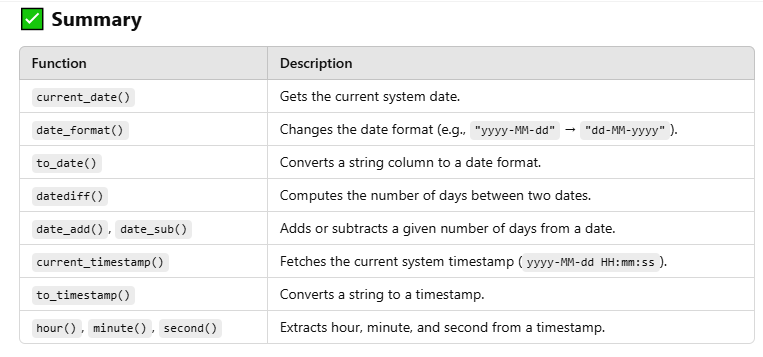